#  Heart Disease Prediction ML Model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = r"C:\Users\rolex\OneDrive\Desktop\Heart Prediction\model\heart_disease_prediction_2026.csv"

df = pd.read_csv(data)

df

,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,57,Male,27.1,Northeast,Middle,Never,Moderate,Light,7,5.7,...,204,0,195,Normal,0,0.9,Downsloping,61.8,19.9,0
1,40,Female,29.0,Northeast,Low,Never,Non-drinker,Sedentary,1,8.0,...,173,0,165,ST-T Abnormality,0,0.5,Downsloping,53.2,48.3,0
2,63,Female,40.1,Southeast,High,Never,Moderate,Sedentary,6,5.5,...,209,0,173,Normal,0,2.3,Downsloping,82.3,5.0,1
3,66,Female,35.5,West,Middle,Never,Heavy,Sedentary,10,7.4,...,187,0,144,Normal,0,1.3,Downsloping,71.1,38.3,1
4,29,Female,19.8,Northeast,High,Current,Non-drinker,Sedentary,8,8.3,...,247,0,170,ST-T Abnormality,0,0.4,Downsloping,74.1,49.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,66,Female,28.7,Midwest,High,Never,Moderate,Very Active,6,6.5,...,242,0,176,Normal,0,0.9,Upsloping,75.5,38.8,0
99996,63,Female,29.6,Midwest,Low,Never,Moderate,Sedentary,8,6.7,...,209,0,171,ST-T Abnormality,0,1.2,Upsloping,68.1,51.5,0
99997,73,Female,20.3,Southeast,High,Never,Non-drinker,Light,8,6.7,...,208,0,165,ST-T Abnormality,1,2.9,Upsloping,65.0,61.0,1
99998,52,Male,27.6,Northeast,Low,Former,Moderate,Very Active,9,8.2,...,142,1,182,Normal,1,1.8,Flat,43.0,52.2,1


In [3]:
df.columns

Index(['age', 'sex', 'bmi', 'region', 'income_level', 'smoking_status',
       'alcohol_intake', 'physical_activity', 'diet_quality', 'sleep_hours',
       'stress_level', 'diabetes', 'hypertension', 'family_history',
       'previous_heart_event', 'resting_bp', 'cholesterol',
       'fasting_blood_sugar', 'max_heart_rate', 'resting_ecg',
       'exercise_angina', 'st_depression', 'st_slope', 'avg_resting_hr',
       'hrv_score', 'heart_disease'],
      dtype='str')

In [4]:
df.corr(numeric_only=True)["heart_disease"].abs().sort_values()


sleep_hours             0.063483
stress_level            0.066525
diet_quality            0.068285
family_history          0.080683
fasting_blood_sugar     0.091742
avg_resting_hr          0.093121
previous_heart_event    0.107727
cholesterol             0.151695
bmi                     0.151921
diabetes                0.177815
hrv_score               0.206058
exercise_angina         0.305310
max_heart_rate          0.318701
resting_bp              0.321985
st_depression           0.330188
hypertension            0.338070
age                     0.457702
heart_disease           1.000000
Name: heart_disease, dtype: float64

In [5]:
df.groupby("region")["heart_disease"].mean()

region
Midwest      0.460375
Northeast    0.462851
Southeast    0.459919
Southwest    0.460487
West         0.460889
Name: heart_disease, dtype: float64

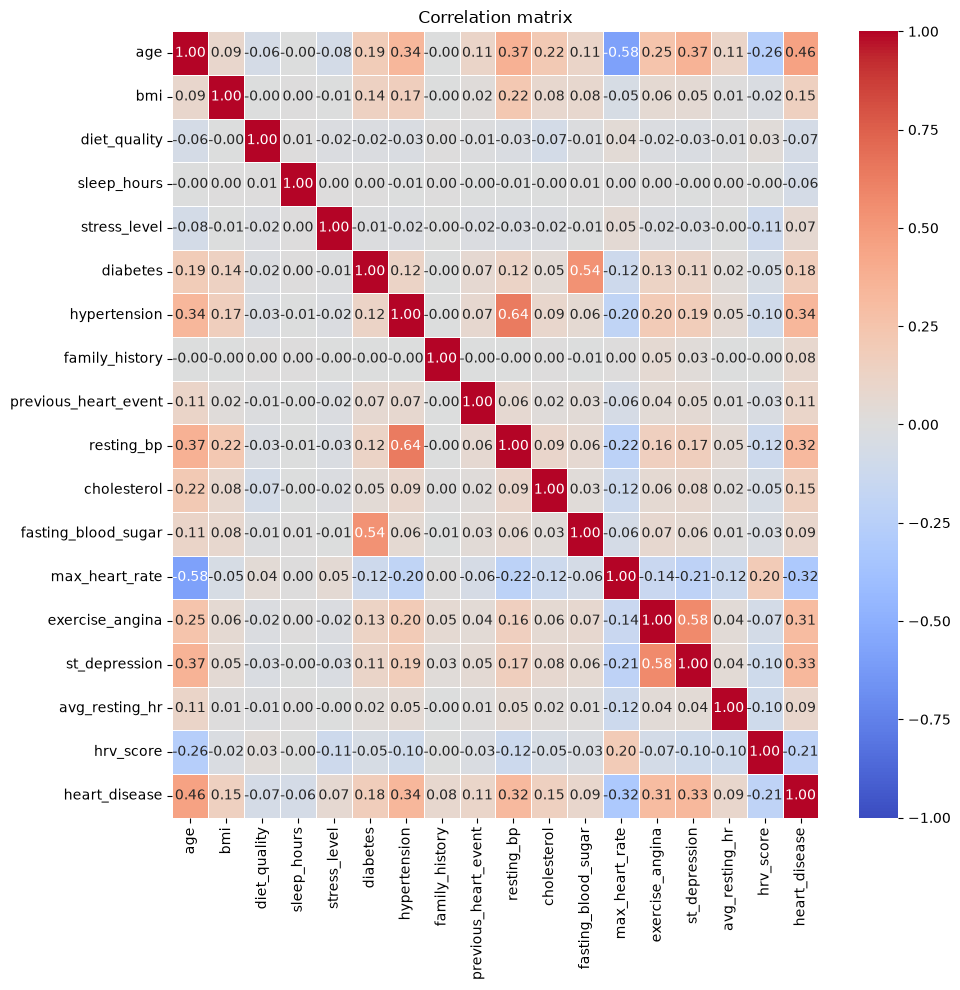

In [6]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 10))
sns.heatmap(
    corr,
    annot=True,  # print the numbers inside the cells
    fmt=".2f",  # 2 decimal places
    cmap="coolwarm",  # red = positive, blue = negative
    vmin=-1,
    vmax=1,  # fixed scale so colors mean the same thing every time
    center=0,
    linewidths=0.5,
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [7]:
X = df.drop(["region","income_level", "heart_disease"], axis=1)
y = df["heart_disease"]

X.shape, y.shape

((100000, 23), (100000,))

In [8]:
for col in df.select_dtypes(include="number").columns:
    print("Skewness of ",col,"--->", df[col].skew())

Skewness of  age ---> 0.04626695368024822
Skewness of  bmi ---> 0.06457138410660518
Skewness of  diet_quality ---> -0.056784246514413605
Skewness of  sleep_hours ---> 0.011422753380137823
Skewness of  stress_level ---> -0.04497179667420286
Skewness of  diabetes ---> 2.4924386002165817
Skewness of  hypertension ---> 0.1207412290666608
Skewness of  family_history ---> 0.8654698511085921
Skewness of  previous_heart_event ---> 5.496406398138779
Skewness of  resting_bp ---> 0.09237687465617885
Skewness of  cholesterol ---> 0.011768041711288946
Skewness of  fasting_blood_sugar ---> 2.0489625811488783
Skewness of  max_heart_rate ---> -0.1708577400400175
Skewness of  exercise_angina ---> 1.1151962607160828
Skewness of  st_depression ---> 1.1462388679300444
Skewness of  avg_resting_hr ---> 0.045581653925119314
Skewness of  hrv_score ---> -0.005494030286435498
Skewness of  heart_disease ---> 0.15720573840283183


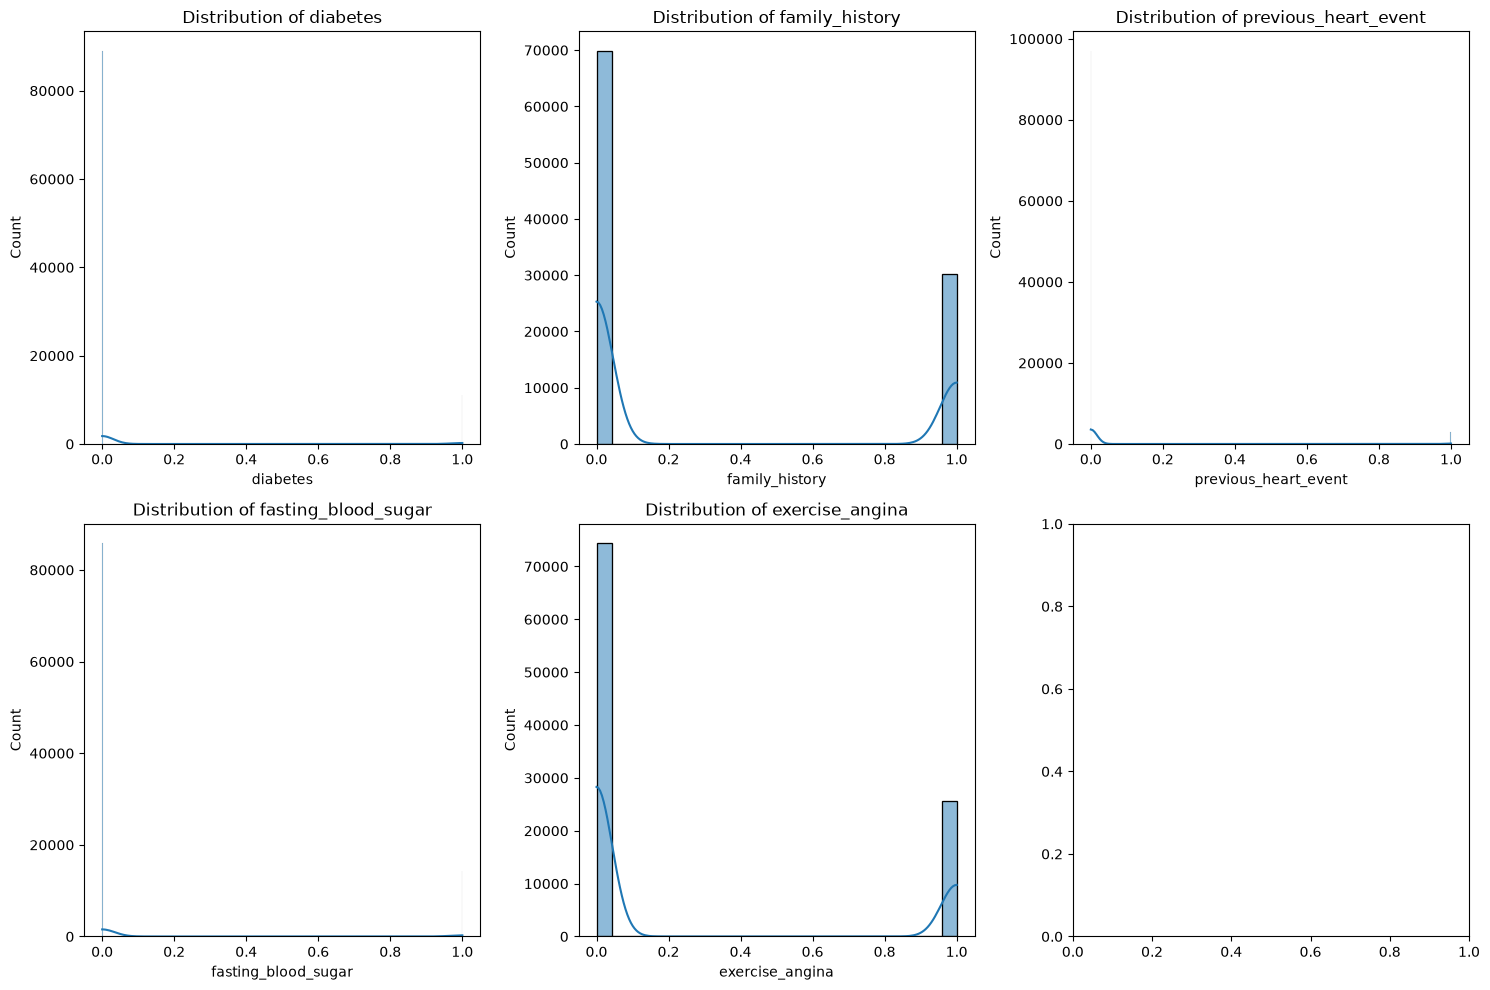

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

binary_features = [
    "diabetes",
    "family_history",
    "previous_heart_event",
    "fasting_blood_sugar",
    "exercise_angina",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, col in zip(axes.flatten(), binary_features):
    sns.histplot(data=X, x=col, kde=True, ax=ax)

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [10]:
summary = pd.DataFrame(
    {
        "min": X.min(numeric_only=True),
        "max": X.max(numeric_only=True),
        "mean": X.mean(numeric_only=True),
        "median": X.median(numeric_only=True),
        "std": X.std(numeric_only=True),
        "variance": X.var(numeric_only=True),
    }
)

print(summary)

                        min    max        mean  median        std     variance
age                    29.0   80.0   53.497760    53.0  12.448859   154.974085
bmi                    15.0   54.6   28.063562    28.0   5.462485    29.838737
diet_quality            1.0   10.0    5.824270     6.0   2.012782     4.051289
sleep_hours             4.0   10.0    6.909246     6.9   1.091675     1.191754
stress_level            1.0   10.0    5.728600     6.0   2.190189     4.796930
diabetes                0.0    1.0    0.110030     0.0   0.312929     0.097924
hypertension            0.0    1.0    0.469870     0.0   0.499094     0.249095
family_history          0.0    1.0    0.301430     0.0   0.458881     0.210572
previous_heart_event    0.0    1.0    0.030140     0.0   0.170973     0.029232
resting_bp             80.0  200.0  142.063750   141.0  25.082072   629.110317
cholesterol           100.0  400.0  217.672840   218.0  48.202876  2323.517282
fasting_blood_sugar     0.0    1.0    0.142200     0

In [11]:

df["heart_disease"].value_counts(normalize=True) * 100

heart_disease
0    53.918
1    46.082
Name: proportion, dtype: float64

In [12]:
import numpy as np

corr = df.drop(columns=["heart_disease"]).corr(numeric_only=True)

high_corr = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(high_corr.head(15))

hypertension     resting_bp             0.637821
age              max_heart_rate        -0.582875
exercise_angina  st_depression          0.577897
diabetes         fasting_blood_sugar    0.538137
age              resting_bp             0.372347
                 st_depression          0.366738
                 hypertension           0.342853
                 hrv_score             -0.261677
                 exercise_angina        0.252484
resting_bp       max_heart_rate        -0.220325
bmi              resting_bp             0.219912
age              cholesterol            0.217330
max_heart_rate   st_depression         -0.212503
hypertension     max_heart_rate        -0.201741
                 exercise_angina        0.200264
dtype: float64


In [13]:
X.isnull().sum()

age                     0
sex                     0
bmi                     0
smoking_status          0
alcohol_intake          0
physical_activity       0
diet_quality            0
sleep_hours             0
stress_level            0
diabetes                0
hypertension            0
family_history          0
previous_heart_event    0
resting_bp              0
cholesterol             0
fasting_blood_sugar     0
max_heart_rate          0
resting_ecg             0
exercise_angina         0
st_depression           0
st_slope                0
avg_resting_hr          0
hrv_score               0
dtype: int64

In [14]:
X.select_dtypes("str")

,sex,smoking_status,alcohol_intake,physical_activity,resting_ecg,st_slope
0,Male,Never,Moderate,Light,Normal,Downsloping
1,Female,Never,Non-drinker,Sedentary,ST-T Abnormality,Downsloping
2,Female,Never,Moderate,Sedentary,Normal,Downsloping
3,Female,Never,Heavy,Sedentary,Normal,Downsloping
4,Female,Current,Non-drinker,Sedentary,ST-T Abnormality,Downsloping
...,...,...,...,...,...,...
99995,Female,Never,Moderate,Very Active,Normal,Upsloping
99996,Female,Never,Moderate,Sedentary,ST-T Abnormality,Upsloping
99997,Female,Never,Non-drinker,Light,ST-T Abnormality,Upsloping
99998,Male,Former,Moderate,Very Active,Normal,Flat


In [15]:
X["smoking_status"].value_counts()

smoking_status
Never      61887
Former     24182
Current    13931
Name: count, dtype: int64

In [16]:
X["alcohol_intake"].value_counts()

alcohol_intake
Moderate       48038
Non-drinker    37898
Heavy          14064
Name: count, dtype: int64

In [17]:
X["physical_activity"].value_counts()

physical_activity
Sedentary      29715
Light          28303
Active         24392
Very Active    17590
Name: count, dtype: int64

In [18]:
X["resting_ecg"].value_counts()

resting_ecg
Normal                          45940
ST-T Abnormality                35486
Left Ventricular Hypertrophy    18574
Name: count, dtype: int64

In [19]:
X["st_slope"].value_counts()

st_slope
Upsloping      42769
Flat           38594
Downsloping    18637
Name: count, dtype: int64

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = ["age", "bmi", "cholesterol", "resting_bp", "hrv_score"]

cat_features = [
    "sex",
    "smoking_status",
    "resting_ecg",
    "st_slope",
    "physical_activity",
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)


In [23]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['age','sex','bmi',...,'st_slope','avg_resting_hr','hrv_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rem

In [24]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    roc_auc_score,
    confusion_matrix,
    recall_score,
    precision_score
)

y_pred = model.predict(X_test)

In [25]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

y_prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("confusion_matrix",cm)
print("ROC-AUC:", auc)
print("classification_report : ")
print(classification_report(y_test, y_pred))

Accuracy: 0.73975
Precision: 0.722983599191193
Recall: 0.7014713896457766
F1 Score: 0.712065055042319
confusion_matrix [[8359 2466]
 [2739 6436]]
ROC-AUC: 0.8172050216788014
classification_report : 
              precision    recall  f1-score   support

           0       0.75      0.77      0.76     10825
           1       0.72      0.70      0.71      9175

    accuracy                           0.74     20000
   macro avg       0.74      0.74      0.74     20000
weighted avg       0.74      0.74      0.74     20000



### Cross-validation ( Verify baseline stability )

In [26]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

print("CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())

CV Scores: [0.7453125 0.7436875 0.7426875 0.742875  0.7325   ]
Mean CV Accuracy: 0.7414124999999998
Std: 0.0045515450673370055


>So our Logistic Regression model is behaving consistently across the folds.

```code
                    Current baseline
                          │
                 ┌────────┴────────┐
                 │                 │
           Test Accuracy      CV Accuracy
              73.98%            74.14%
                 │                 │
                 └────────┬────────┘
                          ↓
                  Stable baseline ✅ 
```

### Feature Quality Analysis (Find weak/useless features)

In [27]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

print(feature_names)

['num__age' 'num__bmi' 'num__cholesterol' 'num__resting_bp'
 'num__hrv_score' 'cat__sex_Female' 'cat__sex_Male'
 'cat__smoking_status_Current' 'cat__smoking_status_Former'
 'cat__smoking_status_Never'
 'cat__resting_ecg_Left Ventricular Hypertrophy' 'cat__resting_ecg_Normal'
 'cat__resting_ecg_ST-T Abnormality' 'cat__st_slope_Downsloping'
 'cat__st_slope_Flat' 'cat__st_slope_Upsloping'
 'cat__physical_activity_Active' 'cat__physical_activity_Light'
 'cat__physical_activity_Sedentary' 'cat__physical_activity_Very Active']


In [28]:
coefficients = model.named_steps["classifier"].coef_[0]

print(coefficients)

[ 0.9607      0.23097634  0.12682554  0.38604457 -0.18725537 -0.2855833
  0.30851368  0.35277197 -0.0433468  -0.28649479  0.31278655 -0.32755488
  0.03769871  0.43495023  0.03662157 -0.44864142 -0.08311345  0.06140693
  0.23725165 -0.19261475]


In [29]:
import pandas as pd

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

coef_df = coef_df.sort_values("abs_coefficient", ascending=False)

print(coef_df)

                                          feature  coefficient  \
0                                        num__age     0.960700   
15                        cat__st_slope_Upsloping    -0.448641   
13                      cat__st_slope_Downsloping     0.434950   
3                                 num__resting_bp     0.386045   
7                     cat__smoking_status_Current     0.352772   
11                        cat__resting_ecg_Normal    -0.327555   
10  cat__resting_ecg_Left Ventricular Hypertrophy     0.312787   
6                                   cat__sex_Male     0.308514   
9                       cat__smoking_status_Never    -0.286495   
5                                 cat__sex_Female    -0.285583   
18               cat__physical_activity_Sedentary     0.237252   
1                                        num__bmi     0.230976   
19             cat__physical_activity_Very Active    -0.192615   
4                                  num__hrv_score    -0.187255   
2         

### Feature Selection Experiment (Lab 3)

In [30]:
drop_features = ["smoking_status", "physical_activity"]
X_reduced = X.drop(columns=drop_features)

In [31]:
from sklearn.model_selection import train_test_split

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42, stratify=y
)

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = ["age", "bmi", "cholesterol", "resting_bp", "hrv_score"]

cat_features = [
    "sex",
    "resting_ecg",
    "st_slope",
]

preprocessor_reduced = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model_reduced = Pipeline(
    [
        ("preprocessor", preprocessor_reduced),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

In [34]:
from sklearn.model_selection import cross_val_score

cv_reduced = cross_val_score(
    model_reduced, X_train_reduced, y_train_reduced, cv=5, scoring="accuracy"
)

print("Reduced Model CV Scores:", cv_reduced)
print("Reduced Model Mean Accuracy:", cv_reduced.mean())
print("Reduced Model Std:", cv_reduced.std())

Reduced Model CV Scores: [0.7340625 0.7390625 0.7390625 0.73925   0.7334375]
Reduced Model Mean Accuracy: 0.7369749999999999
Reduced Model Std: 0.002641495788374458


> so removing the ["smoking_status", "physical_activity"] will decrsing the Model Accuracy so we keep all features as they are

### Try Different Classification Algorithms (Lab 4)

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        ),
    ]
)

In [36]:
from sklearn.model_selection import cross_val_score

rf_cv = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="accuracy")

print("Random Forest CV Scores:", rf_cv)
print("Random Forest Mean Accuracy:", rf_cv.mean())
print("Random Forest Std:", rf_cv.std())

Random Forest CV Scores: [0.7335    0.7338125 0.7356875 0.7305    0.7214375]
Random Forest Mean Accuracy: 0.7309875000000001
Random Forest Std: 0.005056153429238504


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_hgb = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            cat_features,
        ),
    ]
)

In [38]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

hgb_model = Pipeline(
    [
        ("preprocessor", preprocessor_hgb),
        ("classifier", HistGradientBoostingClassifier(random_state=42)),
    ]
)

In [39]:
from sklearn.model_selection import cross_val_score

hgb_cv = cross_val_score(hgb_model, X_train, y_train, cv=5, scoring="accuracy")

print("HistGradientBoosting CV Scores:", hgb_cv)
print("HistGradientBoosting Mean Accuracy:", hgb_cv.mean())
print("HistGradientBoosting Std:", hgb_cv.std())

HistGradientBoosting CV Scores: [0.737     0.7371875 0.738     0.7344375 0.72425  ]
HistGradientBoosting Mean Accuracy: 0.7341749999999999
HistGradientBoosting Std: 0.0051041343536392305


- We tried three fundamentally different approaches:
```code
                    Your dataset
                         │
          ┌──────────────┼──────────────┐
          ↓              ↓              ↓
      Logistic        Random        Gradient
     Regression        Forest        Boosting
          │              │              │
        74.14%         73.10%         73.91%
          │              │              │
          └──────────────┴──────────────┘
                         ↓
                 Logistic Regression wins
```

### Hyperparameter Tuning (Lab 5)

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline(
    [("preprocessor", preprocessor), ("classifier", LogisticRegression(max_iter=1000))]
)

In [41]:
from sklearn.model_selection import GridSearchCV

param_grid = {"classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    estimator=lr_model, param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1
)

In [42]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fi

In [43]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'classifier__C': 0.1}
Best CV Accuracy: 0.7414750000000001


In [44]:
results = grid_search.cv_results_

for mean, std, params in zip(
    results["mean_test_score"], results["std_test_score"], results["params"]
):
    print(params, "→", mean, "±", std)

{'classifier__C': 0.001} → 0.741 ± 0.0049176023121029035
{'classifier__C': 0.01} → 0.741425 ± 0.004670954131652334
{'classifier__C': 0.1} → 0.7414750000000001 ± 0.004427118137118109
{'classifier__C': 1} → 0.7414124999999998 ± 0.0045515450673370055
{'classifier__C': 10} → 0.7413875 ± 0.004572574493652357
{'classifier__C': 100} → 0.7413875 ± 0.004572574493652357


# Final Declaring Best Model 

In [45]:
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# -----------------------------
# Features
# -----------------------------

num_features = ["age", "bmi", "cholesterol", "resting_bp", "hrv_score"]

cat_features = ["sex", "smoking_status", "resting_ecg", "st_slope", "physical_activity"]

# -----------------------------
# Preprocessor
# -----------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ]
)

# -----------------------------
# Final Model
# -----------------------------

final_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=0.1, max_iter=1000)),
    ]
)

# -----------------------------
# Train
# -----------------------------

final_model.fit(X_train, y_train)

# -----------------------------
# Save Model
# -----------------------------

joblib.dump(final_model, "heart_disease_model.pkl")

print("Model saved successfully!")



Model saved successfully!


In [46]:
from sklearn.metrics import accuracy_score

# Predictions using the default threshold = 0.50
y_pred = final_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Final Model Accuracy:", accuracy)
print("Final Model Accuracy (%):", accuracy * 100)

Final Model Accuracy: 0.7398
Final Model Accuracy (%): 73.98


In [48]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

print("Train accuracy:", final_model.score(X_train, y_train))
print("Test accuracy :", final_model.score(X_test, y_test))

print()
print(model.feature_names_in_)

X_train shape: (80000, 23)
y_train shape: (80000,)
X_test shape : (20000, 23)
y_test shape : (20000,)
Train accuracy: 0.7415375
Test accuracy : 0.7398

['age' 'sex' 'bmi' 'smoking_status' 'alcohol_intake' 'physical_activity'
 'diet_quality' 'sleep_hours' 'stress_level' 'diabetes' 'hypertension'
 'family_history' 'previous_heart_event' 'resting_bp' 'cholesterol'
 'fasting_blood_sugar' 'max_heart_rate' 'resting_ecg' 'exercise_angina'
 'st_depression' 'st_slope' 'avg_resting_hr' 'hrv_score']
